# X.9.4. Двухламповый генератор Фрюгауфа
Для состояния $u=(x_1,x_2,y_1,y_2)$ решаем систему
$$
\begin{aligned}
\varepsilon\dot x_1&=-\alpha(y_1-y_2)+\phi(x_1)-x_2, &
\varepsilon\dot x_2&=\alpha(y_1-y_2)+\phi(x_2)-x_1,\\
\dot y_1&=x_1, & \dot y_2&=x_2,\qquad \phi(x)=-\tan(\pi x/2).
\end{aligned}
$$
Начальные данные $u(0)=(0,0,2,0)$, конец интервала $T=20$. В условии задано $\alpha>0$ порядка единицы. В расчётах выбрано $\alpha=1$.

При этих начальных данных симметрия даёт $x_1+x_2=0$ и $y_1+y_2=2$. В начале $\dot x_1=-2/\varepsilon$ и $\dot x_2=2/\varepsilon$. Поэтому рассмотрим отдельно быстрый переход и последующее движение. Первый полюс тангенса находится при $|x_i|=1$.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [22]:
from solvers.explicit_adams import solveExplicitAdams
from solvers.explicit_runge_kutta import solveExplicitRungeKutta
from solvers.implicit_runge_kutta import solveImplicitRungeKutta
from solvers.gear import solveGear

## Эксперимент с шагом интегрирования
Фиксируем $\varepsilon=10^{-3}$ и $\alpha=1$. В каждом прогоне меняется только постоянный шаг $h$ в физическом времени. Все методы начинают с одних начальных данных, включая быстрый переход. Сначала сравним четыре семейства на всём интервале $[0,20]$, затем рассмотрим все порядки 1–4 в начальном слое. В таблицах число означает максимальную абсолютную ошибку по четырём компонентам во всех узлах соответствующей сетки.

In [23]:
alpha = 1.0
eps = 1e-3
u0 = np.array([0., 0., 2., 0.])
T = 20.

def generator(eps):
    # Независимая переменная τ = t/ε. Это сохраняет масштаб невязки стадий НРК.
    def rhs(tau, u):
        x1, x2, y1, y2 = u
        coupling = alpha * (y1 - y2)
        return np.array([-coupling - np.tan(np.pi*x1/2) - x2,
                          coupling - np.tan(np.pi*x2/2) - x1,
                          eps*x1, eps*x2])

    # Производная правой части по состоянию нужна Ньютону на каждом неявном шаге.
    def jac(tau, u):
        d1, d2 = -(np.pi/2) / np.cos(np.pi*u[:2]/2)**2
        return np.array([[d1, -1, -alpha, alpha], [-1, d2, alpha, -alpha],
                         [eps, 0, 0, 0], [0, eps, 0, 0]])
    return rhs, jac

def reference(eps):
    rhs, jac = generator(eps)
    sol = solve_ivp(rhs, (0, T/eps), u0, method="Radau", jac=jac,
                    rtol=2e-11, atol=2e-13, dense_output=True)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.sol

# Независимый контрольный расчёт выполняется один раз при фиксированном ε.
ref = reference(eps)

In [24]:
families = ("РК", "АБ", "НРК", "Гир")

class BranchExit(Exception):
    pass

def check_branch(x):
    if not np.all(np.isfinite(x)) or np.any(np.abs(x) >= 1):
        raise BranchExit

def integrate(family, order, t_end, h):
    # Решатели работают во времени τ. Читатель задаёт h и t_end в физическом времени.
    start, stop, initial = 0., t_end / eps, u0
    count = round(t_end / h)
    assert np.isclose(count*h, t_end, rtol=1e-14, atol=0)
    rhs, jac = generator(eps)
    step = (stop - start) / count
    # Контролируем также промежуточные стадии явных схем возле полюсов тангенса.
    def explicit_rhs(tau, u):
        check_branch(u[:2])
        return rhs(tau, u)

    if family == "РК":
        t, u = solveExplicitRungeKutta(explicit_rhs, initial, start, stop, step, order)
    elif family == "АБ":
        t, u = solveExplicitAdams(explicit_rhs, initial, start, stop, count, order)
    else:
        solver = solveImplicitRungeKutta if family == "НРК" else solveGear
        t, u = solver(rhs, jac, initial, start, stop, step, order)
    u = np.asarray(u)
    check_branch(u[:, :2])
    t = np.asarray(t) * eps
    assert len(t) == count + 1 and np.isclose(t[-1], t_end)
    return t, u

def run(family, order, t_end, h):
    # При срыве расчёта фиксируем причину. Ошибку считаем только у завершённых решений.
    try:
        t, u = integrate(family, order, t_end, h)
    except BranchExit:
        return "полюс", None
    except (RuntimeError, np.linalg.LinAlgError, ValueError) as exc:
        if isinstance(exc, ValueError) and "BiCGSTAB" not in str(exc):
            raise
        return "сбой СНУ", None
    error = np.max(np.abs(u - ref(t / eps).T))
    return f"{error:.2e}", (t, u)

## При каком шаге решение доходит до $t=20$?
Каждая строка — одна равномерная сетка, общая для четырёх методов. Столбец $N=20/h$ позволяет сравнить объём работы в шагах. Время одного шага у методов различается. «Полюс» означает выход узла или явной стадии из ветви $|x_i|<1$, «сбой СНУ» — остановку внутреннего решателя. При оценке ошибки особенно важен первый переход: к концу интервала все точные компоненты уже близки к равновесию.

In [25]:
# Три общих шага от мелкого к крупному. Удвоение h вдвое сокращает число шагов.
steps = T / 2.**np.array([18, 17, 16])
methods = (("РК", 4), ("АБ", 2), ("НРК", 3), ("Гир", 3))
# Сохраняем только траектории, которые ниже понадобятся для рисунков.
curves = {}
print(f"{'h':>13} {'N':>8} " + "".join(f"{family+str(order):>13}" for family, order in methods))
for h in steps:
    row = []
    for family, order in methods:
        entry, trajectory = run(family, order, T, h)
        row.append(entry)
        if trajectory is not None and ((family == "НРК" and h == steps[-1]) or
                                       (family == "РК" and h == steps[0])):
            curves[family] = trajectory
    print(f"{h:13.7f} {round(T/h):8d} " + "".join(f"{entry:>13}" for entry in row))

            h        N           РК4          АБ2         НРК3         Гир3
    0.0000763   262144      1.84e-04     5.70e-03     1.10e-04     1.44e-03
    0.0001526   131072      5.56e-03        полюс     8.06e-04     6.37e-03
    0.0003052    65536         полюс        полюс     4.64e-03     8.43e-03


**Результат для $[0,20]$.** На самом мелком шаге все четыре метода доходят до конца. Первое удвоение шага приводит к выходу АБ2 за полюс, второе — к выходу РК4. При этом НРК3 на самой редкой сетке даёт ошибку 0,00464 за 65 536 шагов. Для сопоставления, РК4 на средней сетке даёт ошибку 0,00556 за 131 072 шага. В этой задаче НРК3 использует **вдвое более крупный шаг при сопоставимой точности**. Метод Гира третьего порядка также проходит самую редкую сетку с ошибкой 0,00843.

## Как шаг влияет на начальный переход?
На участке $0\le t\le32\varepsilon$ удобно проверить все порядки. Первая строка каждой таблицы соответствует самому мелкому шагу. На этом участке быстрые компоненты успевают резко измениться, поэтому даже завершённый расчёт может дать большую ошибку.

In [26]:
layer_end = 32*eps
layer_steps = eps * np.array([1/64, 1/16, 1/8, 1/4, 1/2, 1])
for family in families:
    print(f"\n{family} — максимальная ошибка в начальном слое")
    print(f"{'h':>12}" + "".join(f"{family+str(p):>12}" for p in range(1, 5)))
    for h in layer_steps:
        # Сравниваем все порядки на одной сетке, затем переходим к следующему h.
        row = [run(family, p, layer_end, h)[0] for p in range(1, 5)]
        print(f"{h:12.8f}" + "".join(f"{value:>12}" for value in row))


РК — максимальная ошибка в начальном слое
           h         РК1         РК2         РК3         РК4
  0.00001563    5.87e-03    1.17e-04    6.75e-06    2.07e-07
  0.00006250    2.49e-02    2.37e-03    4.98e-04    7.28e-05
  0.00012500    5.57e-02    1.43e-02    3.89e-03    1.99e-03
  0.00025000    8.35e-01    1.23e-01    9.26e-02    1.74e-01
  0.00050000       полюс       полюс       полюс       полюс
  0.00100000       полюс       полюс       полюс       полюс

АБ — максимальная ошибка в начальном слое
           h         АБ1         АБ2         АБ3         АБ4
  0.00001563    5.87e-03    2.56e-04    2.41e-05    4.61e-06
  0.00006250    2.49e-02    3.84e-03    4.01e-01       полюс
  0.00012500    5.57e-02    4.92e-01       полюс       полюс
  0.00025000    8.35e-01       полюс       полюс       полюс
  0.00050000       полюс       полюс       полюс       полюс
  0.00100000       полюс       полюс       полюс       полюс

НРК — максимальная ошибка в начальном слое
           h    

При $h=0{,}0005$ все явные схемы выходят из исходной ветви уже в начальном слое. На этом же шаге Гир3 завершает расчёт с ошибкой около 0,029, а у НРК3 останавливается внутренний решатель. Допустимый шаг зависит и от конкретной неявной схемы, и от сходимости её внутренних итераций.

## Быстрый переход крупным планом
На каждой фигуре показана одна численная траектория $x_1(t)$. У двух рисунков одинаковые границы осей. Точки обозначают вычисленные узлы: по расстоянию между ними видно, насколько различаются шаги.

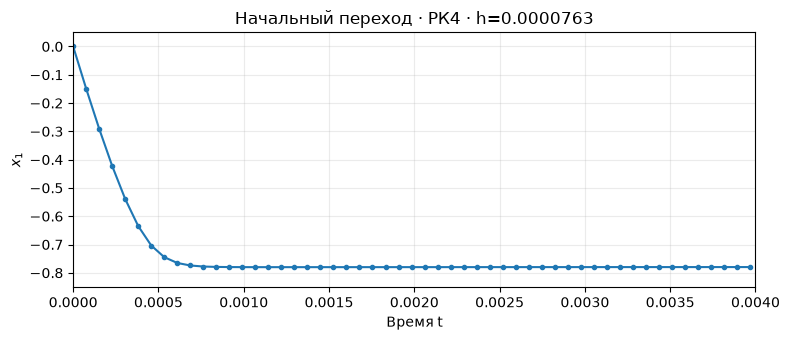

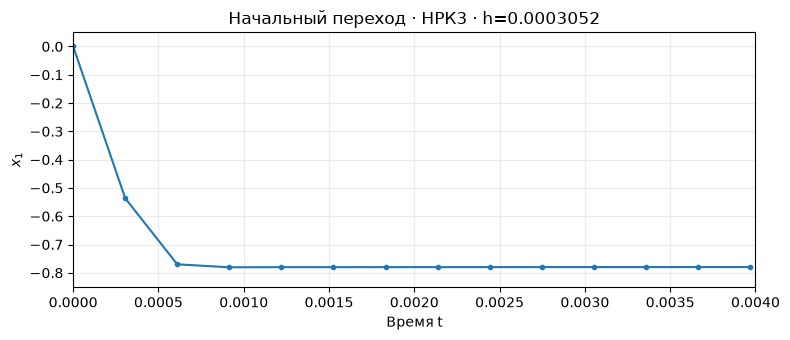

In [27]:
for family, order, h in (("РК", 4, steps[0]), ("НРК", 3, steps[-1])):
    # Создаём новую фигуру для каждого метода. Оставляем только первые 0,004 единицы времени.
    t, u = curves[family]
    mask = t <= 4*eps
    plt.figure(figsize=(8, 3.5))
    plt.plot(t[mask], u[mask, 0], ".-")
    plt.xlim(0, 4*eps)
    plt.ylim(-0.85, 0.05)
    plt.xlabel("Время t")
    plt.ylabel("$x_1$")
    plt.title(f"Начальный переход · {family}{order} · h={h:.7f}")
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.show()

## Решение на всём интервале
Для четырёх интегральных кривых берём расчёт НРК3 на самом крупном шаге основной таблицы. Каждый рисунок показывает одну компоненту от $t=0$ до $t=20$.

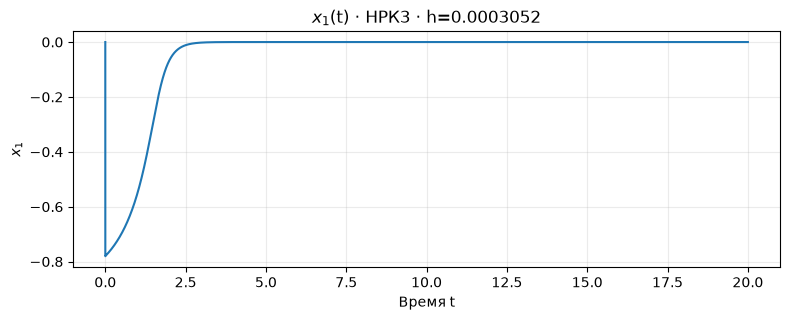

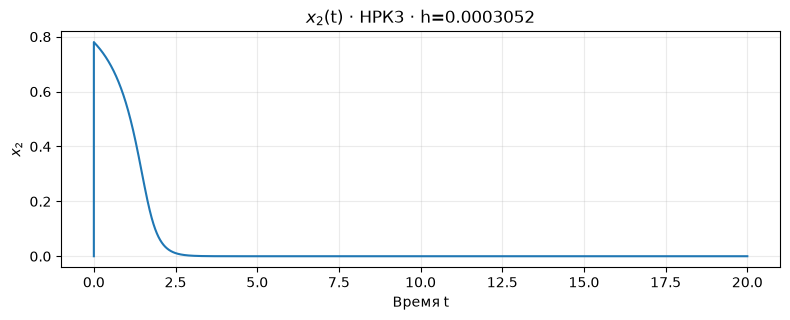

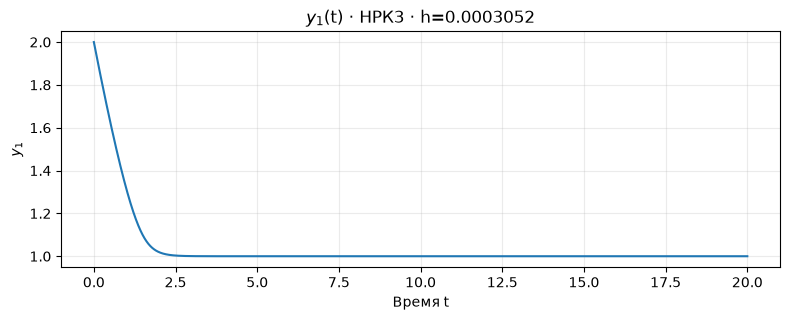

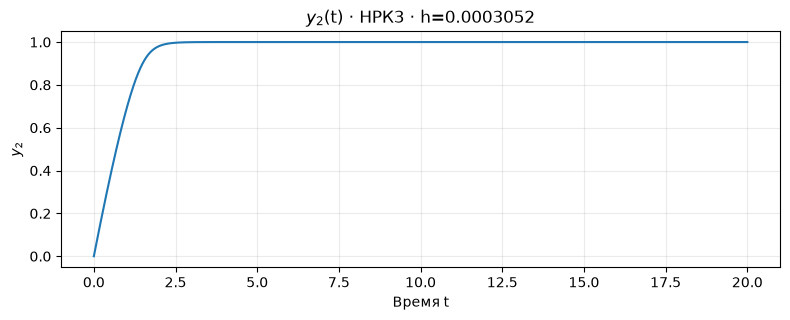

In [28]:
t, u = curves["НРК"]
for j, name in enumerate(("$x_1$", "$x_2$", "$y_1$", "$y_2$")):
    # Столбец j массива u содержит значение выбранной компоненты во всех узлах.
    plt.figure(figsize=(8, 3.3))
    plt.plot(t, u[:, j])
    plt.xlabel("Время t")
    plt.ylabel(name)
    plt.title(f"{name}(t) · НРК3 · h={steps[-1]:.7f}")
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.show()

## Почему траектория приходит к равновесию
На симметричной траектории положим $x=x_1=-x_2$ и $z=y_1-1=1-y_2$. Тогда $\dot z=x$ и $\varepsilon\dot x=-2\alpha z+x-\tan(\pi x/2)$. Для энергии $E=\varepsilon x^2/2+\alpha z^2$ получаем
$$\dot E=x^2-x\tan(\pi x/2).$$
На исходной ветви $|x|<1$ энергия строго убывает при $x\ne0$, поскольку $|\tan(\pi x/2)|>|x|$. Поэтому для этих начальных данных замкнутый цикл невозможен. В расчёте к $t=20$ обе медленные компоненты приближаются к единице, а быстрые — к нулю.

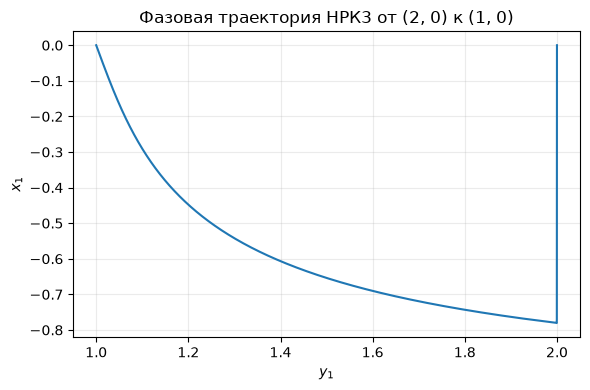

In [29]:
# По горизонтали медленная компонента y₁, по вертикали быстрая x₁ того же решения.
plt.figure(figsize=(6, 4))
plt.plot(u[:, 2], u[:, 0])
plt.xlabel("$y_1$")
plt.ylabel("$x_1$")
plt.title("Фазовая траектория НРК3 от (2, 0) к (1, 0)")
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()